In [186]:
#load libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.font_manager as fm
import glob
import string
from tabulate import tabulate
import os
from pathlib import Path
import shutil
import geopandas as gpd
from shapely.geometry import Point, Polygon, LineString, box
from tqdm import tqdm
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
import math
import time
from shapely.ops import unary_union
import seaborn as sns
from scipy.spatial import cKDTree
import matplotlib.cm as cm
from matplotlib.patches import Circle
from collections import defaultdict
import pyomo.environ as pyo
import gurobipy as gp
import osmnx as ox, networkx as nx
from osmnx.distance import nearest_nodes
from descartes import PolygonPatch
import requests
import matplotlib.colors as colors
import pickle
from datetime import datetime
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

today = datetime.today().strftime("%Y%m%d")

In [187]:
ROOT_DIR = Path.cwd()
DATA_DIR = ROOT_DIR / 'intermediate_result'
RESULTS_DIR = ROOT_DIR / 'results'

In [188]:
gdf_bogun = gpd.read_file(DATA_DIR / 'gdf_bogun.gpkg', encoding="utf-8-sig")
gdf_bogun.index = gdf_bogun.index.astype(str)

In [189]:
def load_selected_facilities_revised(mode, N, LAMBDA_, T, coeff, equity, base_dir = RESULTS_DIR / "optimization_results"):
    tag_map = {"free": "free", "sgg_fixed": "sgg_fixed", "sgg_relaxed": "sgg_relaxed"}
    tag = tag_map[mode]
    tag_map_1 = {"base" : "base", "revised" : "revised"}
    tag_1 = tag_map_1[equity]
    pattern = f"*_{tag}_N{N}_lambda{LAMBDA_}_T{T}_{tag_1}_coeff{coeff}.pkl"
    candidates = sorted((Path(base_dir).glob(pattern)),
                        key=lambda p: p.stat().st_mtime, reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No file matched: {pattern} in {base_dir}")
    path = candidates[0]
    with open(path, "rb") as f:
        data = pickle.load(f)
    return data, path

In [190]:
lambda_ = 0.5
mode = "free"
n = 200

In [191]:
selected, p = load_selected_facilities_revised(mode, N = n, LAMBDA_=lambda_, T=0.5, coeff=5.0, equity = "base")
selected_1, p_1 = load_selected_facilities_revised(mode, N = n, LAMBDA_=lambda_, T=0.5, coeff=1.0, equity = "revised")
selected_2, p_2 = load_selected_facilities_revised(mode, N = n, LAMBDA_=lambda_, T=0.5, coeff=1.5, equity = "revised")
selected_3, p_3 = load_selected_facilities_revised(mode, N = n, LAMBDA_=lambda_, T=0.5, coeff=2.0, equity = "revised")
selected_4, p_4 = load_selected_facilities_revised(mode, N = n, LAMBDA_=lambda_, T=0.5, coeff=5.0, equity = "revised")

In [192]:
gdf_bogun_0 = gdf_bogun.loc[gdf_bogun.index.isin(selected)]
gdf_bogun_1 = gdf_bogun.loc[gdf_bogun.index.isin(selected_1)]
gdf_bogun_2 = gdf_bogun.loc[gdf_bogun.index.isin(selected_2)]
gdf_bogun_3 = gdf_bogun.loc[gdf_bogun.index.isin(selected_3)]
gdf_bogun_4 = gdf_bogun.loc[gdf_bogun.index.isin(selected_4)]

In [193]:
import math
import pandas as pd

def recompute_grid_accessibility(
    selected_facilities,
    grid_to_inst,
    a_dict,
    Cij
):
    selected_set = set(selected_facilities)

    records = []

    for i, inst_dict in grid_to_inst.items():
        a_i = a_dict[i]

        # 선택된 시설 중 격자 i에 영향 주는 후보
        candidates = [
            j for j in inst_dict.keys()
            if j in selected_set
        ]

        chosen_j = None
        z_i = 0.0

        for j in candidates:
            # j보다 가까운 선택 시설이 있으면 탈락
            closer = Cij.get((i, j), [])
            if any(c in selected_set for c in closer):
                continue
            chosen_j = j
            z_i = inst_dict[j]
            break  # 하나만 허용

        p_i = math.sqrt(a_i + z_i)

        records.append({
            "grid_id": i,
            "a_before": a_i,
            "z": z_i,
            "a_after": a_i + z_i,
            "delta": p_i - math.sqrt(a_i),
            "chosen_facility": chosen_j
        })

    return pd.DataFrame(records)

In [194]:
path = Path(DATA_DIR / "Cij.pkl")
with open(path, "rb") as f:
    Cij = pickle.load(f)

path = Path(DATA_DIR / "a_dict.pkl")
with open(path, "rb") as f:
    a_dict = pickle.load(f)

path = Path(DATA_DIR / "grid_to_inst.pkl")
with open(path, "rb") as f:
    grid_to_inst = pickle.load(f)

In [195]:
gdf_grid_pop = pd.read_csv(DATA_DIR / 'gdf_grid_pop.csv')
gdf_emd = pd.read_csv(DATA_DIR / 'gdf_emd.csv')

In [196]:
gdf_emd

,EMD_CD,EMD_ENG_NM,EMD_KOR_NM,geometry
0,11110101,Cheongun-dong,청운동,POLYGON ((953700.0221347539 1954605.0654306228...
1,11110102,Singyo-dong,신교동,POLYGON ((953233.4654317541 1953996.9839332262...
2,11110103,Gungjeong-dong,궁정동,POLYGON ((953560.2281430522 1954257.4664824517...
3,11110104,Hyoja-dong,효자동,POLYGON ((953519.8434113949 1953890.7847365611...
4,11110105,Changseong-dong,창성동,"POLYGON ((953516.1234310449 1953734.362012191,..."
...,...,...,...,...
5061,52800380,Baeksan-myeon,백산면,POLYGON ((934492.4348348521 1747398.2656658462...
5062,52800390,Sangseo-myeon,상서면,POLYGON ((924979.6382929038 1740610.2141194607...
5063,52800400,Haseo-myeon,하서면,POLYGON ((924910.5630196838 1749481.9848055744...
5064,52800410,Julpo-myeon,줄포면,POLYGON ((929554.1881591459 1736493.3992894848...


In [197]:
from shapely import wkt
gdf_grid_pop['grid_centroid'] = gdf_grid_pop['grid_centroid'].apply(wkt.loads)
gdf_grid_pop['geometry'] = gdf_grid_pop['geometry'].apply(wkt.loads)
gdf_grid_pop = gpd.GeoDataFrame(
    gdf_grid_pop,
    geometry="geometry",
    crs="EPSG:5179"
)

gdf_emd['geometry'] = gdf_emd['geometry'].apply(wkt.loads)
gdf_emd = gpd.GeoDataFrame(
    gdf_emd,
    geometry="geometry",
    crs="EPSG:5179"
)   

In [198]:
df_grid = recompute_grid_accessibility(selected, grid_to_inst, a_dict, Cij)
df_grid_1 = recompute_grid_accessibility(selected_1, grid_to_inst, a_dict, Cij)
df_grid_2 = recompute_grid_accessibility(selected_2, grid_to_inst, a_dict, Cij)
df_grid_3 = recompute_grid_accessibility(selected_3, grid_to_inst, a_dict, Cij)
df_grid_4 = recompute_grid_accessibility(selected_4, grid_to_inst, a_dict, Cij)

In [199]:
df_grid["grid_id"] = df_grid["grid_id"].astype(str)
df_grid_1["grid_id"] = df_grid_1["grid_id"].astype(str)
df_grid_2["grid_id"] = df_grid_2["grid_id"].astype(str)
df_grid_3["grid_id"] = df_grid_3["grid_id"].astype(str)
df_grid_4["grid_id"] = df_grid_4["grid_id"].astype(str)
gdf_grid_pop.index = gdf_grid_pop.index.astype(str)

In [200]:
df_grid = df_grid.merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how='inner')
df_grid_1 = df_grid_1.merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how='inner')
df_grid_2 = df_grid_2.merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how='inner')
df_grid_3 = df_grid_3.merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how='inner')
df_grid_4 = df_grid_4.merge(gdf_grid_pop, left_on = "grid_id", right_index = True, how='inner')

In [201]:
df_grid = df_grid.drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
df_grid_1 = df_grid_1.drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
df_grid_2 = df_grid_2.drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
df_grid_3 = df_grid_3.drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])
df_grid_4 = df_grid_4.drop(columns = ['GRID_500M_', '법정동코드', 'node_id', 'offset_to_node_m'])

In [202]:
df_grid = gpd.GeoDataFrame(
    df_grid,
    geometry='geometry',
    crs=gdf_grid_pop.crs
)
df_grid_1 = gpd.GeoDataFrame(
    df_grid_1,
    geometry='geometry',
    crs=gdf_grid_pop.crs
)
df_grid_2 = gpd.GeoDataFrame(
    df_grid_2,
    geometry='geometry',
    crs=gdf_grid_pop.crs
)
df_grid_3 = gpd.GeoDataFrame(
    df_grid_3,
    geometry='geometry',
    crs=gdf_grid_pop.crs
)

In [203]:
df_grid['vulnerable'] = (df_grid['a_before'] < 0.5)
df_grid_1['vulnerable'] = (df_grid_1['a_before'] < 0.5)
df_grid_2['vulnerable'] = (df_grid_2['a_before'] < 0.5)
df_grid_3['vulnerable'] = (df_grid_3['a_before'] < 0.5)
df_grid_4['vulnerable'] = (df_grid_4['a_before'] < 0.5)
df_grid['resolved'] = (df_grid['vulnerable'] & (df_grid['a_after'] > 0.5))
df_grid_1['resolved'] = (df_grid_1['vulnerable'] & (df_grid_1['a_after'] > 0.5))
df_grid_2['resolved'] = (df_grid_2['vulnerable'] & (df_grid_2['a_after'] > 0.5))
df_grid_3['resolved'] = (df_grid_3['vulnerable'] & (df_grid_3['a_after'] > 0.5))
df_grid_4['resolved'] = (df_grid_4['vulnerable'] & (df_grid_4['a_after'] > 0.5))

In [204]:
df_grid_vulnerable = df_grid[df_grid['vulnerable'] == True]
df_grid_vulnerable_1 = df_grid_1[df_grid_1['vulnerable'] == True]
df_grid_vulnerable_2 = df_grid_2[df_grid_2['vulnerable'] == True]
df_grid_vulnerable_3 = df_grid_3[df_grid_3['vulnerable'] == True]
df_grid_vulnerable_4 = df_grid_4[df_grid_4['vulnerable'] == True]

In [205]:
df_grid['improved accessibility'] = df_grid['adjusted_population'] * df_grid['delta']
df_grid_1['improved accessibility'] = df_grid_1['adjusted_population'] * df_grid_1['delta']
df_grid_2['improved accessibility'] = df_grid_2['adjusted_population'] * df_grid_2['delta']
df_grid_3['improved accessibility'] = df_grid_3['adjusted_population'] * df_grid_3['delta']
df_grid_4['improved accessibility'] = df_grid_4['adjusted_population'] * df_grid_4['delta']
df_grid_vulnerable['improved accessibility'] = df_grid_vulnerable['adjusted_population'] * df_grid_vulnerable['delta']
df_grid_vulnerable_1['improved accessibility'] = df_grid_vulnerable_1['adjusted_population'] * df_grid_vulnerable_1['delta']
df_grid_vulnerable_2['improved accessibility'] = df_grid_vulnerable_2['adjusted_population'] * df_grid_vulnerable_2['delta']
df_grid_vulnerable_3['improved accessibility'] = df_grid_vulnerable_3['adjusted_population'] * df_grid_vulnerable_3['delta']
df_grid_vulnerable_4['improved accessibility'] = df_grid_vulnerable_4['adjusted_population'] * df_grid_vulnerable_4['delta']

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .l

In [206]:
df_grid_nonvul = df_grid.loc[~df_grid["grid_id"].isin(df_grid_vulnerable["grid_id"])]
df_grid_nonvul_1 = df_grid_1.loc[~df_grid_1["grid_id"].isin(df_grid_vulnerable_1["grid_id"])]
df_grid_nonvul_2 = df_grid_2.loc[~df_grid_2["grid_id"].isin(df_grid_vulnerable_2["grid_id"])]
df_grid_nonvul_3 = df_grid_3.loc[~df_grid_3["grid_id"].isin(df_grid_vulnerable_3["grid_id"])]
df_grid_nonvul_4 = df_grid_4.loc[~df_grid_4["grid_id"].isin(df_grid_vulnerable_4["grid_id"])]

In [207]:
df_grid_resolved = df_grid_vulnerable[df_grid_vulnerable['resolved'] == True]
df_grid_resolved_1 = df_grid_vulnerable_1[df_grid_vulnerable_1['resolved'] == True]
df_grid_resolved_2 = df_grid_vulnerable_2[df_grid_vulnerable_2['resolved'] == True]
df_grid_resolved_3 = df_grid_vulnerable_3[df_grid_vulnerable_3['resolved'] == True]
df_grid_resolved_4 = df_grid_vulnerable_4[df_grid_vulnerable_4['resolved'] == True]

In [208]:
print("---------------------------------------------------------------------------")
print(f"추가 격자(1.0) : {set(df_grid_resolved_1['grid_id']) - set(df_grid_resolved['grid_id']), set(df_grid_resolved['grid_id']) - set(df_grid_resolved_1['grid_id'])}")
print(f"추가 격자(1.5) : {set(df_grid_resolved_2['grid_id']) - set(df_grid_resolved['grid_id']), set(df_grid_resolved['grid_id']) - set(df_grid_resolved_2['grid_id'])}")
print(f"추가 격자(2.0) : {set(df_grid_resolved_3['grid_id']) - set(df_grid_resolved['grid_id']), set(df_grid_resolved['grid_id']) - set(df_grid_resolved_3['grid_id'])}")
print(f"추가 격자(5.0) : {set(df_grid_resolved_4['grid_id']) - set(df_grid_resolved['grid_id']), set(df_grid_resolved['grid_id']) - set(df_grid_resolved_4['grid_id'])}")
print(f"보건소 변화(1.0) : {set(selected) - set(selected_1), set(selected_1) - set(selected)}")
print(f"보건소 변화(1.5) : {set(selected) - set(selected_2), set(selected_2) - set(selected)}")
print(f"보건소 변화(2.0) : {set(selected) - set(selected_3), set(selected_3) - set(selected)}")
print(f"보건소 변화(5.0) : {set(selected) - set(selected_4), set(selected_4) - set(selected)}")

---------------------------------------------------------------------------
추가 격자(1.0) : ({'24965', '24975', '231333', '338101', '338091', '14568', '24966', '365829', '338282', '338200', '24976', '218400', '384126', '338061', '24974', '249364', '221329', '14731', '338118', '24972', '214348', '365904', '24960', '24973', '338218'}, {'181080', '92416', '199318', '95150', '91840', '374087', '38256', '37697', '279509', '95254', '84602', '66049', '38257', '224214', '311635', '279530', '224203', '199280', '257758', '279672', '94978', '257703', '311632', '241907', '179432', '311630', '199436', '257700', '265921', '38276', '395330', '265991', '222729', '95155', '265940', '199279', '279555', '223599', '223602', '257737', '38163', '391120', '224213', '257781', '241894', '263036', '223661', '224208', '279557', '95226', '180830', '38280', '92455', '84425', '180829', '223573', '243486', '180933', '91839', '223416', '257760', '38252', '311380', '199435', '180919', '95256', '92423', '27452', '241999',

In [209]:
print(f"n : {n}, mode : {mode}, lambda : {lambda_}")
print("---------------------------------------------------------------------------")
# base 결과 print
print(f"해소 취약격자 갯수(base) : {len(df_grid_vulnerable[df_grid_vulnerable['a_after'] > 0.5])}")
print(f"접근성 상승 취약격자 갯수(base) : {len(df_grid_vulnerable[df_grid_vulnerable['z'] > 0])}")
print(f"취약격자 접근성 향상(base) : {df_grid_vulnerable['z'].sum()}")
print(f"취약격자 접근성 분산(base) : {np.var(df_grid_vulnerable['a_after'])}")
print("---------------------------------------------------------------------------")
# coeff = 1.0 결과 print
print(f"해소 취약격자 갯수(1.0) : {len(df_grid_vulnerable_1[df_grid_vulnerable_1['a_after'] > 0.5])}")
print(f"접근성 상승 취약격자 갯수(1.0) : {len(df_grid_vulnerable_1[df_grid_vulnerable_1['z'] > 0])}")
print(f"취약격자 접근성 향상(1.0) : {df_grid_vulnerable_1['z'].sum()}")
print(f"취약격자 접근성 분산(1.0) : {np.var(df_grid_vulnerable_1['a_after'])}")
print("---------------------------------------------------------------------------")
# coeff = 1.5 결과 print
print(f"해소 취약격자 갯수(1.5) : {len(df_grid_vulnerable_2[df_grid_vulnerable_2['a_after'] > 0.5])}")
print(f"접근성 상승 취약격자 갯수(1.5) : {len(df_grid_vulnerable_2[df_grid_vulnerable_2['z'] > 0])}")
print(f"취약격자 접근성 향상(1.5) : {df_grid_vulnerable_2['z'].sum()}")
print(f"취약격자 접근성 분산(1.5) : {np.var(df_grid_vulnerable_2['a_after'])}")
print("---------------------------------------------------------------------------")
# coeff = 2.0 결과 print
print(f"해소 취약격자 갯수(2.0) : {len(df_grid_vulnerable_3[df_grid_vulnerable_3['a_after'] > 0.5])}")
print(f"접근성 상승 취약격자 갯수(2.0) : {len(df_grid_vulnerable_3[df_grid_vulnerable_3['z'] > 0])}")
print(f"취약격자 접근성 향상(2.0) : {df_grid_vulnerable_3['z'].sum()}")
print(f"취약격자 접근성 분산(2.0) : {np.var(df_grid_vulnerable_3['a_after'])}")
print("---------------------------------------------------------------------------")
# coeff = 5.0 결과 print
print(f"해소 취약격자 갯수(5.0) : {len(df_grid_vulnerable_4[df_grid_vulnerable_4['a_after'] > 0.5])}")
print(f"접근성 상승 취약격자 갯수(5.0) : {len(df_grid_vulnerable_4[df_grid_vulnerable_4['z'] > 0])}")
print(f"취약격자 접근성 향상(5.0) : {df_grid_vulnerable_4['z'].sum()}")
print(f"취약격자 접근성 분산(5.0) : {np.var(df_grid_vulnerable_4['a_after'])}")
print("---------------------------------------------------------------------------")
grid_id = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_1))][df_grid['vulnerable'] == True]['grid_id']
print(f"base 배치안 없을 때 해소 취약격자 갯수(1.0) : {len(df_grid_1[df_grid_1['grid_id'].isin(grid_id)][df_grid_1['resolved'] == True])}")
grid_id = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_2))][df_grid['vulnerable'] == True]['grid_id']
print(f"base 배치안 없을 때 해소 취약격자 갯수(1.5) : {len(df_grid_2[df_grid_2['grid_id'].isin(grid_id)][df_grid_2['resolved'] == True])}")
grid_id = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_3))][df_grid['vulnerable'] == True]['grid_id']
print(f"base 배치안 없을 때 해소 취약격자 갯수(2.0) : {len(df_grid_3[df_grid_3['grid_id'].isin(grid_id)][df_grid_3['resolved'] == True])}")
grid_id = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_4))][df_grid['vulnerable'] == True]['grid_id']
print(f"base 배치안 없을 때 해소 취약격자 갯수(5.0) : {len(df_grid_4[df_grid_4['grid_id'].isin(grid_id)][df_grid_4['resolved'] == True])}")
print("---------------------------------------------------------------------------")
print(f"location 이후 취약격자 접근성 평균(base) : {df_grid[df_grid['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 1.0) : {df_grid_1[df_grid_1['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이전 취약격자 접근성 평균(coeff : 1.0 / 기존) : {df_grid_1[df_grid_1['chosen_facility'].isin(set(selected_1) - set(selected))][df_grid_1['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 1.0 / 기존) : {df_grid_1[df_grid_1['chosen_facility'].isin(set(selected_1) - set(selected))][df_grid_1['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 1.5) : {df_grid_2[df_grid_2['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이전 취약격자 접근성 평균(coeff : 1.5 / 기존) : {df_grid_2[df_grid_2['chosen_facility'].isin(set(selected_2) - set(selected))][df_grid_2['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 1.5 / 기존) : {df_grid_2[df_grid_2['chosen_facility'].isin(set(selected_2) - set(selected))][df_grid_2['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 2.0) : {df_grid_3[df_grid_3['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이전 취약격자 접근성 평균(coeff : 2.0 / 기존) : {df_grid_3[df_grid_3['chosen_facility'].isin(set(selected_3) - set(selected))][df_grid_3['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 2.0 / 기존) : {df_grid_3[df_grid_3['chosen_facility'].isin(set(selected_3) - set(selected))][df_grid_3['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 5.0) : {df_grid_4[df_grid_4['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이전 취약격자 접근성 평균(coeff : 5.0 / 기존) : {df_grid_4[df_grid_4['chosen_facility'].isin(set(selected_4) - set(selected))][df_grid_4['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 5.0 / 기존) : {df_grid_4[df_grid_4['chosen_facility'].isin(set(selected_4) - set(selected))][df_grid_4['vulnerable'] == True]['a_after'].mean()}")
print("---------------------------------------------------------------------------")
print(f"향상된 인구 고려 접근성(base) : {df_grid[df_grid['adjusted_population'] != 0]['improved accessibility'].sum()}")
print(f"향상된 인구 고려 접근성(coeff : 1.0) : {df_grid_1[df_grid_1['adjusted_population'] != 0]['improved accessibility'].sum()}")
print(f"향상된 인구 고려 접근성(coeff : 1.5) : {df_grid_2[df_grid_2['adjusted_population'] != 0]['improved accessibility'].sum()}")
print(f"향상된 인구 고려 접근성(coeff : 2.0) : {df_grid_3[df_grid_3['adjusted_population'] != 0]['improved accessibility'].sum()}")
print(f"향상된 인구 고려 접근성(coeff : 5.0) : {df_grid_4[df_grid_4['adjusted_population'] != 0]['improved accessibility'].sum()}")
print("---------------------------------------------------------------------------")
print(f"향상된 인구 고려 접근성(base)(취약격자 제외) : {df_grid_nonvul[df_grid_nonvul['adjusted_population'] != 0]['improved accessibility'].sum()}")
print(f"향상된 인구 고려 접근성(coeff : 1.0)(취약격자 제외) : {df_grid_nonvul_1[df_grid_nonvul_1['adjusted_population'] != 0]['improved accessibility'].sum()}")
print(f"향상된 인구 고려 접근성(coeff : 1.5)(취약격자 제외) : {df_grid_nonvul_2[df_grid_nonvul_2['adjusted_population'] != 0]['improved accessibility'].sum()}")
print(f"향상된 인구 고려 접근성(coeff : 2.0)(취약격자 제외) : {df_grid_nonvul_3[df_grid_nonvul_3['adjusted_population'] != 0]['improved accessibility'].sum()}")
print(f"향상된 인구 고려 접근성(coeff : 5.0)(취약격자 제외) : {df_grid_nonvul_4[df_grid_nonvul_4['adjusted_population'] != 0]['improved accessibility'].sum()}")

n : 200, mode : free, lambda : 0.5
---------------------------------------------------------------------------
해소 취약격자 갯수(base) : 8009
접근성 상승 취약격자 갯수(base) : 9571
취약격자 접근성 향상(base) : 4925.809444005026
취약격자 접근성 분산(base) : 0.07496269497657262
---------------------------------------------------------------------------
해소 취약격자 갯수(1.0) : 7779
접근성 상승 취약격자 갯수(1.0) : 9371
취약격자 접근성 향상(1.0) : 4792.805143264757
취약격자 접근성 분산(1.0) : 0.07673463596804886
---------------------------------------------------------------------------
해소 취약격자 갯수(1.5) : 7931
접근성 상승 취약격자 갯수(1.5) : 9533
취약격자 접근성 향상(1.5) : 4868.2299968628995
취약격자 접근성 분산(1.5) : 0.07495488198927365
---------------------------------------------------------------------------
해소 취약격자 갯수(2.0) : 7972
접근성 상승 취약격자 갯수(2.0) : 9655
취약격자 접근성 향상(2.0) : 4882.612098790284
취약격자 접근성 분산(2.0) : 0.07382862239307547
---------------------------------------------------------------------------
해소 취약격자 갯수(5.0) : 8000
접근성 상승 취약격자 갯수(5.0) : 9699
취약격자 접근성 향상(5.0) : 4902.03

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaco

In [210]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch
import numpy as np

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47308 (\N{HANGUL SYLLABLE RYO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49444 (\N{HANGUL SYLLABLE SEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51217 (\N{HANGUL SYLLABLE JEOB}) missing from font(s) 

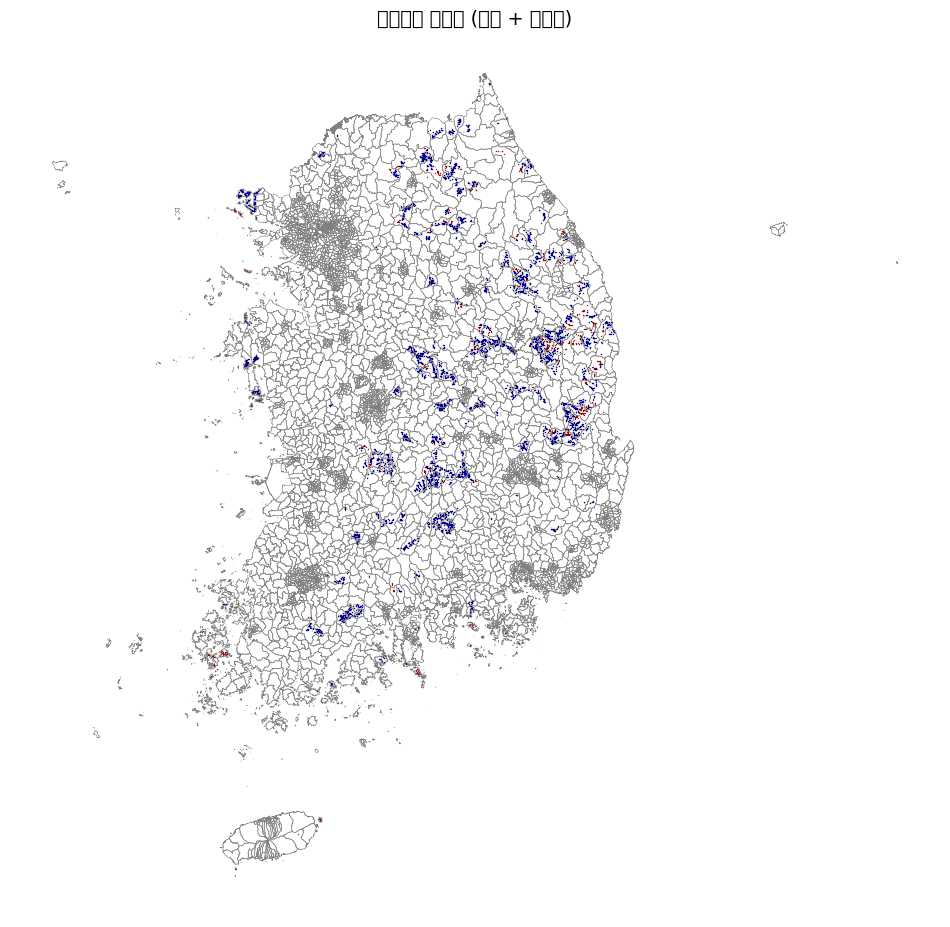

In [211]:
fig, ax = plt.subplots(figsize=(12, 14))

# 격자
df_grid_vulnerable.plot(
    ax=ax,
    facecolor='red',
    edgecolor='black',
    markersize=10,
    linewidth=0.1,
    alpha=1.0
)

df_grid_resolved.plot(
    ax=ax,
    facecolor='blue',
    edgecolor='black',
    markersize=10,
    linewidth=0.1,
    alpha=1.0
)

# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

ax.set_title('의료시설 접근성 (격자 + 읍면동)', fontsize=14)
ax.axis('off')

plt.show()

In [212]:
df_grid_only_base_1 = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_1))]
df_grid_only_base_2 = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_2))]
df_grid_only_base_3 = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_3))]
df_grid_only_base_4 = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_4))]
df_grid_only_1 = df_grid_1[df_grid_1['chosen_facility'].isin(set(selected_1) - set(selected))]
df_grid_only_2 = df_grid_2[df_grid_2['chosen_facility'].isin(set(selected_2) - set(selected))]
df_grid_only_3 = df_grid_3[df_grid_3['chosen_facility'].isin(set(selected_3) - set(selected))]
df_grid_only_4 = df_grid_4[df_grid_4['chosen_facility'].isin(set(selected_4) - set(selected))]

In [213]:
emd_access = df_grid.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_1 = df_grid_1.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_2 = df_grid_2.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_3 = df_grid_3.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_4 = df_grid_4.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")

In [214]:
emd_access_only_base_1 = df_grid_only_base_1.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_base_2 = df_grid_only_base_2.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_base_3 = df_grid_only_base_3.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_base_4 = df_grid_only_base_4.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_1 = df_grid_only_1.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_2 = df_grid_only_2.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_3 = df_grid_only_3.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")
emd_access_only_4 = df_grid_only_4.groupby("EMD_CD")["improved accessibility"].sum().reset_index(name="access_sum")

In [215]:
gdf_emd_access = gdf_emd.merge(emd_access, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_1 = gdf_emd.merge(emd_access_1, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_2 = gdf_emd.merge(emd_access_2, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_3 = gdf_emd.merge(emd_access_3, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_4 = gdf_emd.merge(emd_access_4, on="EMD_CD", how = "left").fillna({"access_sum": 0})

In [216]:
gdf_emd_access_only_base_1 = gdf_emd.merge(emd_access_only_base_1, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_base_2 = gdf_emd.merge(emd_access_only_base_2, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_base_3 = gdf_emd.merge(emd_access_only_base_3, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_base_4 = gdf_emd.merge(emd_access_only_base_4, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_1 = gdf_emd.merge(emd_access_only_1, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_2 = gdf_emd.merge(emd_access_only_2, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_3 = gdf_emd.merge(emd_access_only_3, on="EMD_CD", how = "left").fillna({"access_sum": 0})
gdf_emd_access_only_4 = gdf_emd.merge(emd_access_only_4, on="EMD_CD", how = "left").fillna({"access_sum": 0})

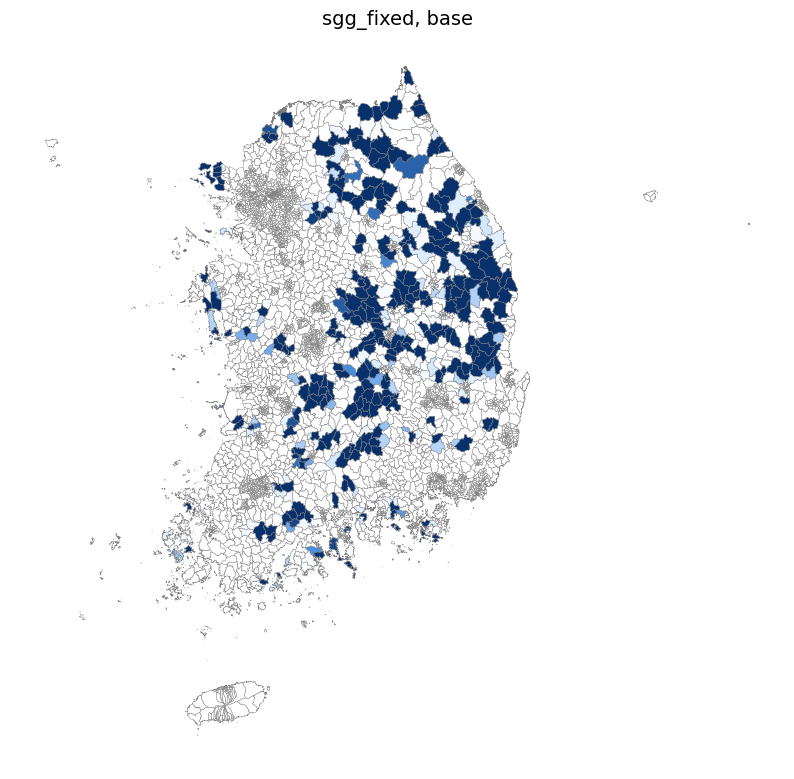

In [217]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "white_to_blue",
    ["#ffffff", "#cce5ff", "#4a90e2", "#08306b"]
)

fig, ax = plt.subplots(figsize=(10, 12))

vmax = np.abs(gdf_emd_access["access_sum"]).quantile(0.95)
vmin = 0

gdf_emd_access.plot(
    column="access_sum",
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    legend=False,
    #legend_kwds={'shrink' : 0.3},
    edgecolor="gray",
    linewidth=0.3,
    ax=ax
)

ax.set_title("sgg_fixed, base", fontsize=14)
ax.axis("off")
plt.show()

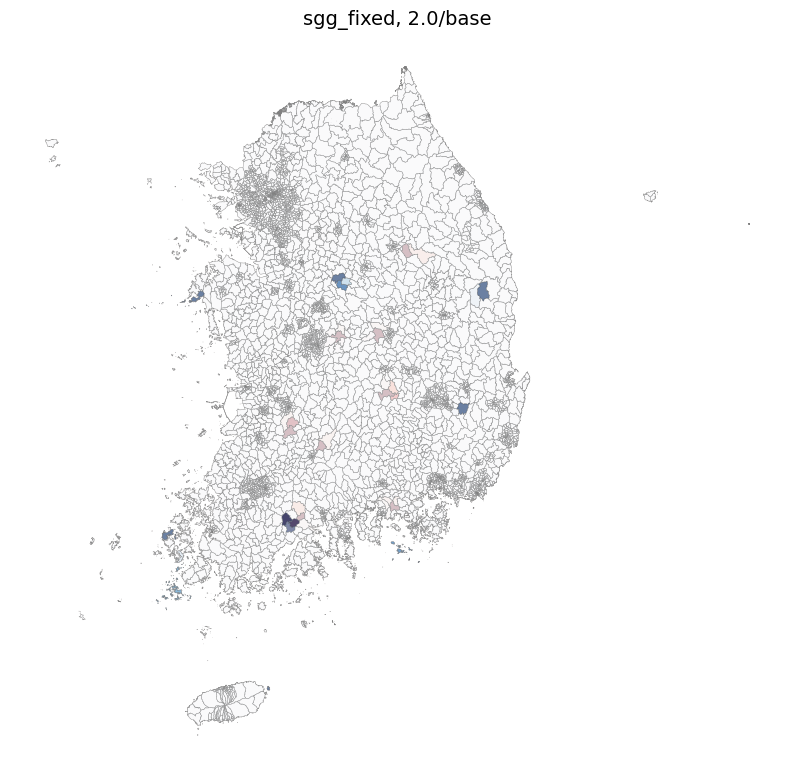

In [218]:
from matplotlib.colors import LinearSegmentedColormap

# cmap = LinearSegmentedColormap.from_list(
#     "white_to_blue",
#     ["#ffffff", "#cce5ff", "#4a90e2", "#08306b"]
# )

fig, ax = plt.subplots(figsize=(10, 12))

vmax = np.abs(gdf_emd_access["access_sum"]).quantile(0.95)
vmin = 0

gdf_emd_access_only_base_3.plot(
    column="access_sum",
    cmap='Reds',
    vmin=vmin,
    vmax=vmax,
    legend=False,
    #legend_kwds={'shrink' : 0.3},
    edgecolor="gray",
    linewidth=0.3,
    alpha=0.6,
    ax=ax
)

gdf_emd_access_only_3.plot(
    column="access_sum",
    cmap='Blues',
    vmin=vmin,
    vmax=vmax,
    legend=False,
    #legend_kwds={'shrink' : 0.3},
    edgecolor="gray",
    linewidth=0.3,
    alpha=0.6,
    ax=ax
)

ax.set_title("sgg_fixed, 2.0/base", fontsize=14)
ax.axis("off")
plt.show()

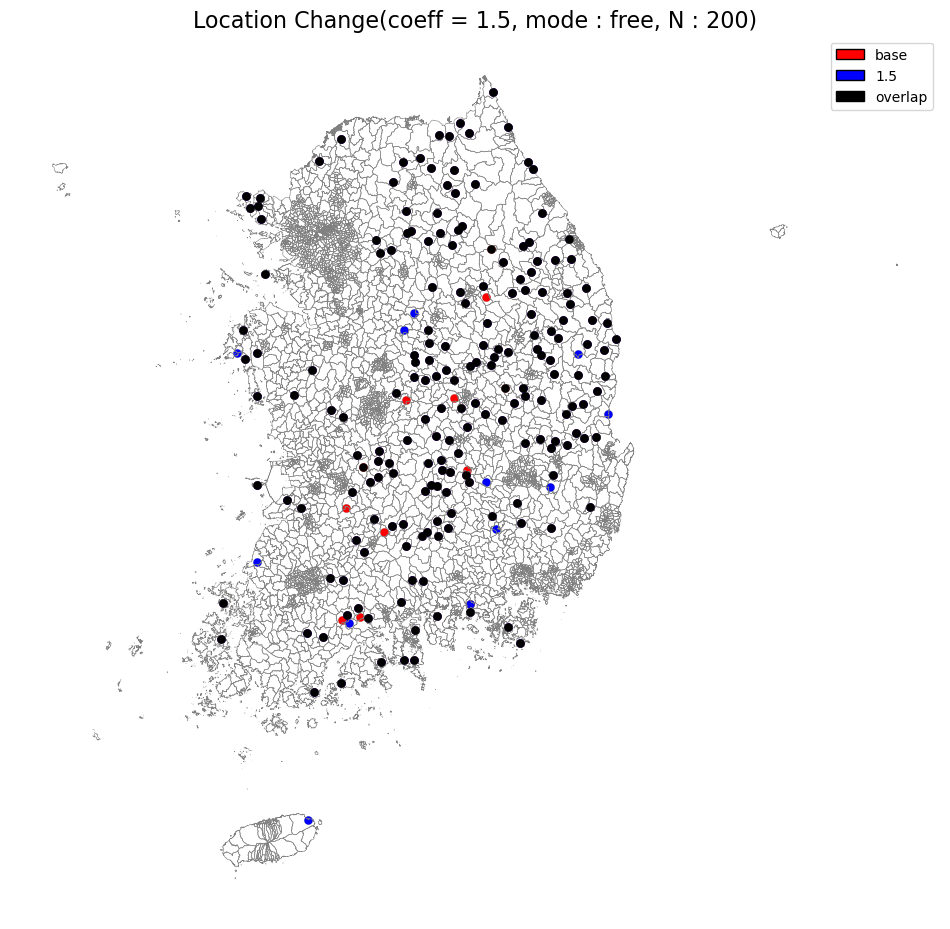

In [219]:
fig, ax = plt.subplots(figsize=(12, 14))

# 보건소
gdf_bogun_overlap = gdf_bogun.loc[gdf_bogun.index.isin(set(selected_3) & set(selected))]

gdf_bogun_0.plot(
    ax=ax,
    facecolor='red',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_2.plot(
    ax=ax,
    facecolor='blue',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_overlap.plot(
    ax=ax,
    facecolor='black',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 10
)


# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

legend_elements = [
    Patch(facecolor='red',  edgecolor='black', label='base'),
    Patch(facecolor='blue',   edgecolor='black', label='1.5'),
    Patch(facecolor='black',   edgecolor='black', label='overlap')
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=10,
    title_fontsize=11
)

ax.set_title(f"Location Change(coeff = 1.5, mode : {mode}, N : {n})", fontsize=16)
ax.axis('off')

plt.show()

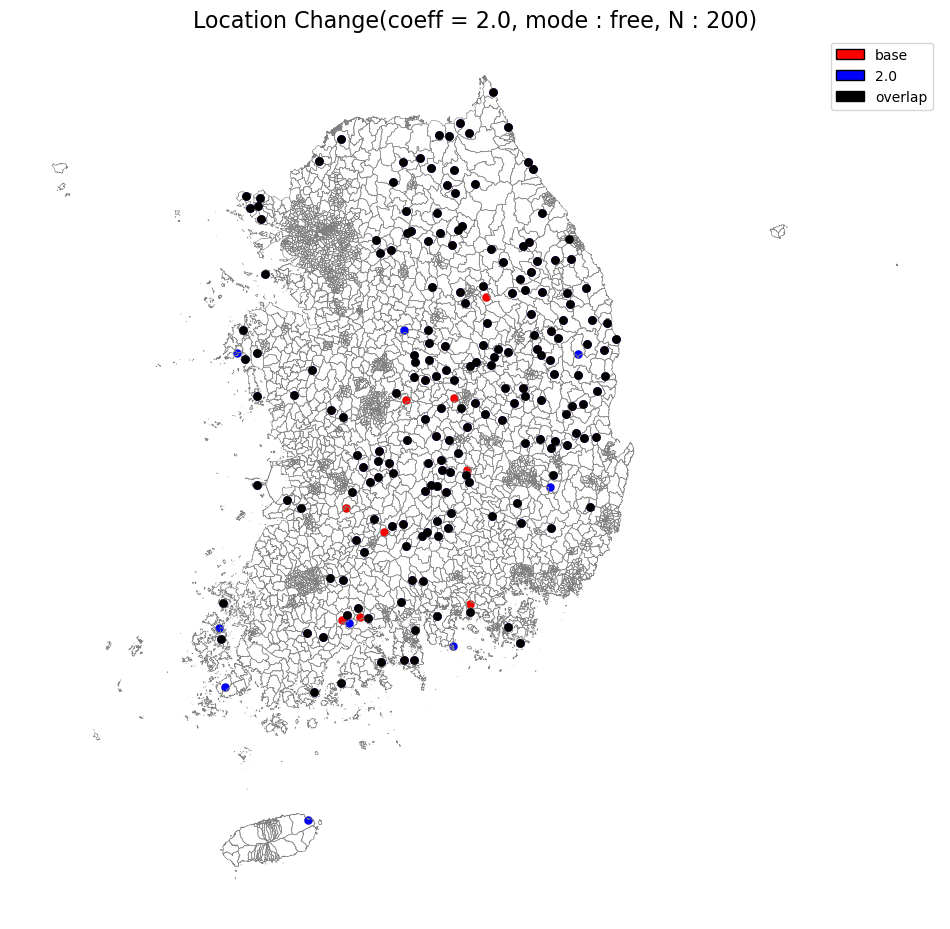

In [220]:
fig, ax = plt.subplots(figsize=(12, 14))

# 보건소
gdf_bogun_overlap = gdf_bogun.loc[gdf_bogun.index.isin(set(selected_3) & set(selected))]

gdf_bogun_0.plot(
    ax=ax,
    facecolor='red',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_3.plot(
    ax=ax,
    facecolor='blue',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_overlap.plot(
    ax=ax,
    facecolor='black',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 10
)


# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

legend_elements = [
    Patch(facecolor='red',  edgecolor='black', label='base'),
    Patch(facecolor='blue',   edgecolor='black', label='2.0'),
    Patch(facecolor='black',   edgecolor='black', label='overlap')
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=10,
    title_fontsize=11
)

ax.set_title(f"Location Change(coeff = 2.0, mode : {mode}, N : {n})", fontsize=16)
ax.axis('off')

plt.show()

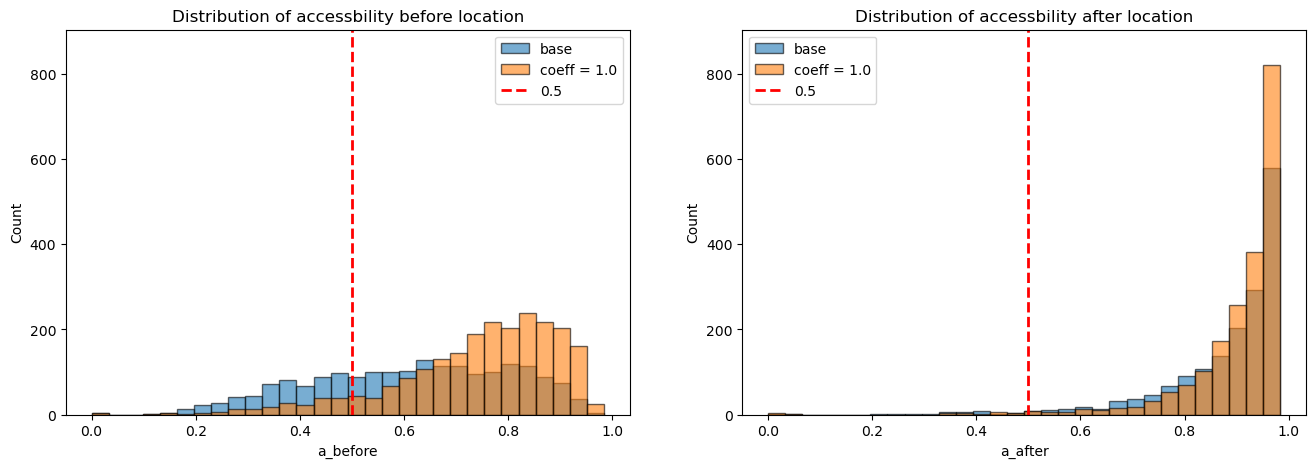

In [221]:
fig, axes = plt.subplots(1,2,figsize=(16, 5))

ax1, ax2 = axes

data_all = np.concatenate([
    df_grid_only_base_1['a_before'],
    df_grid_only_1['a_before']
])

bins = np.histogram_bin_edges(data_all, bins=30)

ax1.hist(
    df_grid_only_base_1['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax1.hist(
    df_grid_only_1['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 1.0',
    edgecolor='black'
)

ax1.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax1.set_title('Distribution of accessbility before location')
ax1.set_xlabel('a_before')
ax1.set_ylabel('Count')
ax1.legend()

ax2.hist(
    df_grid_only_base_1['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax2.hist(
    df_grid_only_1['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 1.0',
    edgecolor='black'
)

ax2.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax2.set_title('Distribution of accessbility after location')
ax2.set_xlabel('a_after')
ax2.set_ylabel('Count')
ax2.legend()

# 히스토그램 count 계산 (그리지는 않음)
c1, _ = np.histogram(df_grid_only_base_1['a_before'].dropna(), bins=bins)
c2, _ = np.histogram(df_grid_only_1['a_before'].dropna(), bins=bins)
c3, _ = np.histogram(df_grid_only_base_1['a_after'].dropna(), bins=bins)
c4, _ = np.histogram(df_grid_only_1['a_after'].dropna(), bins=bins)

ymax = max(c1.max(), c2.max(), c3.max(), c4.max())

ax1.set_ylim(0, ymax * 1.1)
ax2.set_ylim(0, ymax * 1.1)

plt.show()

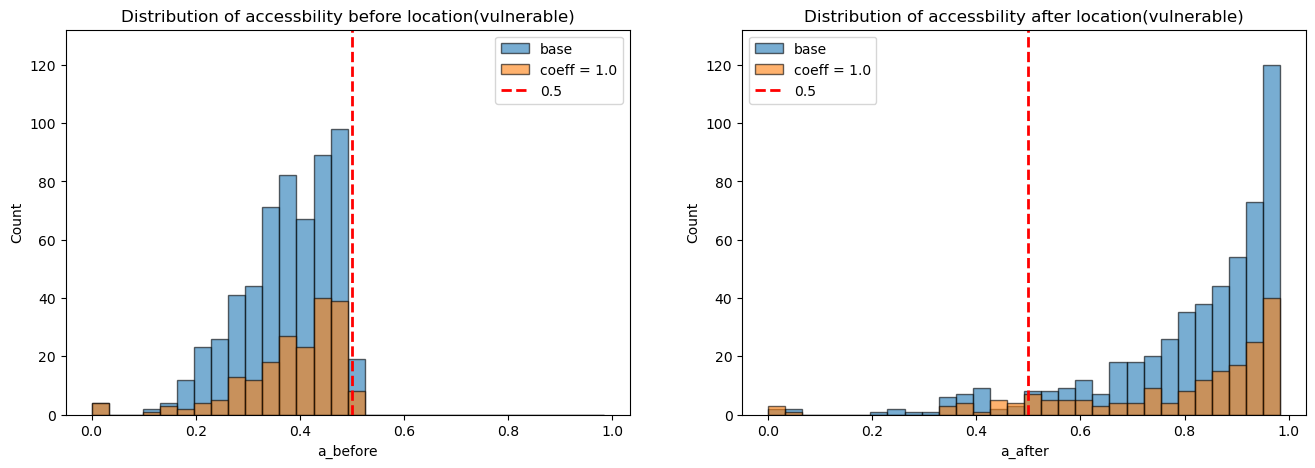

In [222]:
fig, axes = plt.subplots(1,2,figsize=(16, 5))

ax1, ax2 = axes

data_all = np.concatenate([
    df_grid_only_base_1['a_before'],
    df_grid_only_1['a_before']
])

bins = np.histogram_bin_edges(data_all, bins=30)

ax1.hist(
    df_grid_only_base_1[df_grid_only_base_1['vulnerable'] == True]['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax1.hist(
    df_grid_only_1[df_grid_only_1['vulnerable'] == True]['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 1.0',
    edgecolor='black'
)

ax1.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax1.set_title('Distribution of accessbility before location(vulnerable)')
ax1.set_xlabel('a_before')
ax1.set_ylabel('Count')
ax1.legend()

ax2.hist(
    df_grid_only_base_1[df_grid_only_base_1['vulnerable'] == True]['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax2.hist(
    df_grid_only_1[df_grid_only_1['vulnerable'] == True]['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 1.0',
    edgecolor='black'
)

ax2.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax2.set_title('Distribution of accessbility after location(vulnerable)')
ax2.set_xlabel('a_after')
ax2.set_ylabel('Count')
ax2.legend()

# 히스토그램 count 계산 (그리지는 않음)
c1, _ = np.histogram(df_grid_only_base_1[df_grid_only_base_1['vulnerable'] == True]['a_before'].dropna(), bins=bins)
c2, _ = np.histogram(df_grid_only_1[df_grid_only_1['vulnerable'] == True]['a_before'].dropna(), bins=bins)
c3, _ = np.histogram(df_grid_only_base_1[df_grid_only_base_1['vulnerable'] == True]['a_after'].dropna(), bins=bins)
c4, _ = np.histogram(df_grid_only_1[df_grid_only_1['vulnerable'] == True]['a_after'].dropna(), bins=bins)

ymax = max(c1.max(), c2.max(), c3.max(), c4.max())

ax1.set_ylim(0, ymax * 1.1)
ax2.set_ylim(0, ymax * 1.1)

plt.show()

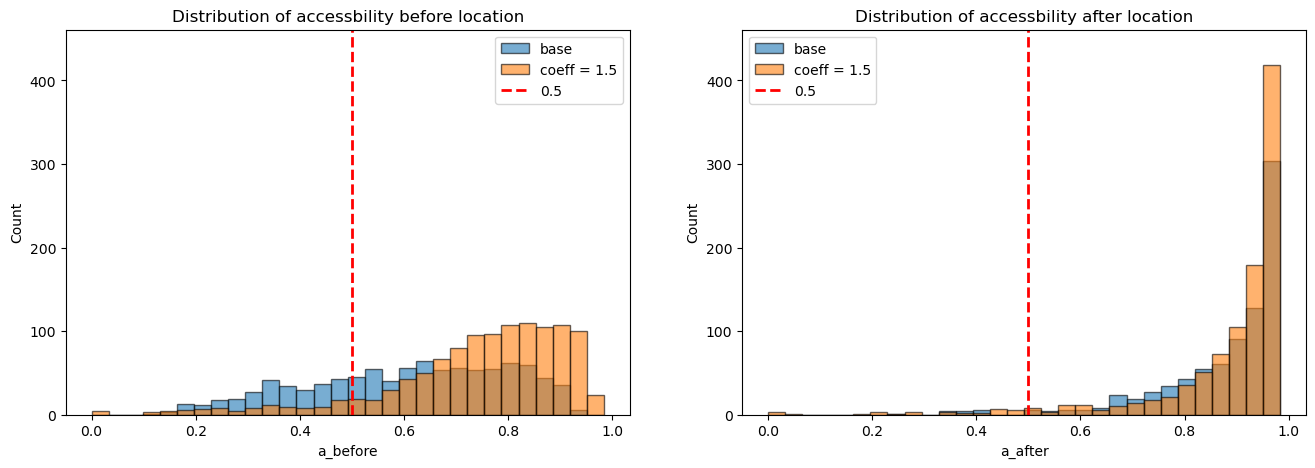

In [223]:
fig, axes = plt.subplots(1,2,figsize=(16, 5))

ax1, ax2 = axes

data_all = np.concatenate([
    df_grid_only_base_2['a_before'],
    df_grid_only_2['a_before']
])

bins = np.histogram_bin_edges(data_all, bins=30)

ax1.hist(
    df_grid_only_base_2['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax1.hist(
    df_grid_only_2['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 1.5',
    edgecolor='black'
)

ax1.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax1.set_title('Distribution of accessbility before location')
ax1.set_xlabel('a_before')
ax1.set_ylabel('Count')
ax1.legend()

ax2.hist(
    df_grid_only_base_2['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax2.hist(
    df_grid_only_2['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 1.5',
    edgecolor='black'
)

ax2.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax2.set_title('Distribution of accessbility after location')
ax2.set_xlabel('a_after')
ax2.set_ylabel('Count')
ax2.legend()

# 히스토그램 count 계산 (그리지는 않음)
c1, _ = np.histogram(df_grid_only_base_2['a_before'].dropna(), bins=bins)
c2, _ = np.histogram(df_grid_only_2['a_before'].dropna(), bins=bins)
c3, _ = np.histogram(df_grid_only_base_2['a_after'].dropna(), bins=bins)
c4, _ = np.histogram(df_grid_only_2['a_after'].dropna(), bins=bins)

ymax = max(c1.max(), c2.max(), c3.max(), c4.max())

ax1.set_ylim(0, ymax * 1.1)
ax2.set_ylim(0, ymax * 1.1)

plt.show()

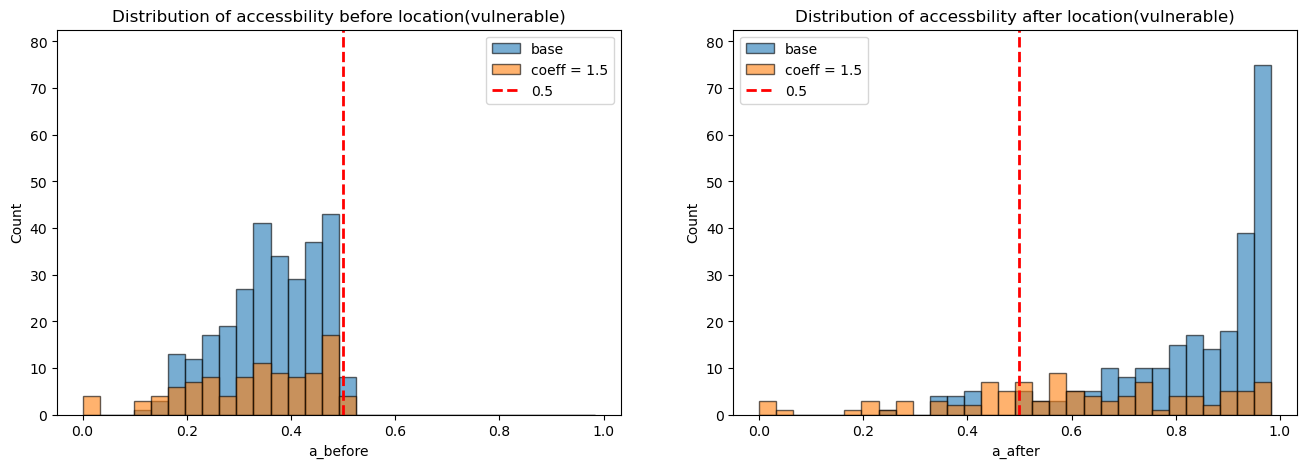

In [224]:
fig, axes = plt.subplots(1,2,figsize=(16, 5))

ax1, ax2 = axes

data_all = np.concatenate([
    df_grid_only_base_2['a_before'],
    df_grid_only_2['a_before']
])

bins = np.histogram_bin_edges(data_all, bins=30)

ax1.hist(
    df_grid_only_base_2[df_grid_only_base_2['vulnerable'] == True]['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax1.hist(
    df_grid_only_2[df_grid_only_2['vulnerable'] == True]['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 1.5',
    edgecolor='black'
)

ax1.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax1.set_title('Distribution of accessbility before location(vulnerable)')
ax1.set_xlabel('a_before')
ax1.set_ylabel('Count')
ax1.legend()

ax2.hist(
    df_grid_only_base_2[df_grid_only_base_2['vulnerable'] == True]['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax2.hist(
    df_grid_only_2[df_grid_only_2['vulnerable'] == True]['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 1.5',
    edgecolor='black'
)

ax2.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax2.set_title('Distribution of accessbility after location(vulnerable)')
ax2.set_xlabel('a_after')
ax2.set_ylabel('Count')
ax2.legend()

# 히스토그램 count 계산 (그리지는 않음)
c1, _ = np.histogram(df_grid_only_base_2[df_grid_only_base_2['vulnerable'] == True]['a_before'].dropna(), bins=bins)
c2, _ = np.histogram(df_grid_only_2[df_grid_only_2['vulnerable'] == True]['a_before'].dropna(), bins=bins)
c3, _ = np.histogram(df_grid_only_base_2[df_grid_only_base_2['vulnerable'] == True]['a_after'].dropna(), bins=bins)
c4, _ = np.histogram(df_grid_only_2[df_grid_only_2['vulnerable'] == True]['a_after'].dropna(), bins=bins)

ymax = max(c1.max(), c2.max(), c3.max(), c4.max())

ax1.set_ylim(0, ymax * 1.1)
ax2.set_ylim(0, ymax * 1.1)

plt.show()

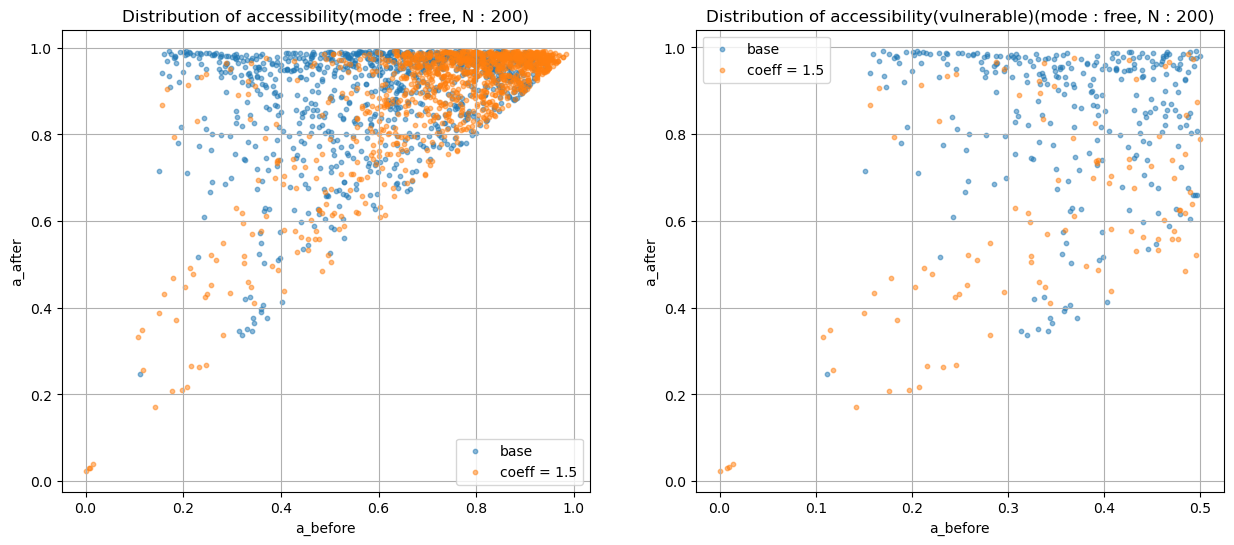

In [225]:
# coeff = 1.5, accessibility scatter

fig, axes = plt.subplots(1,2,figsize=(15, 6))

ax1, ax2 = axes

ax1.scatter(
    df_grid_only_base_2['a_before'],
    df_grid_only_base_2['a_after'],
    s=10,
    alpha=0.5,
    label='base'
)

ax1.scatter(
    df_grid_only_2['a_before'],
    df_grid_only_2['a_after'],
    s=10,
    alpha=0.5,
    label='coeff = 1.5'
)

ax1.set_title(f'Distribution of accessibility(mode : {mode}, N : {n})')
ax1.set_xlabel('a_before')
ax1.set_ylabel('a_after')
ax1.legend()
ax1.grid(True)

ax2.scatter(
    df_grid_only_base_2[df_grid_only_base_2['vulnerable'] == True]['a_before'],
    df_grid_only_base_2[df_grid_only_base_2['vulnerable'] == True]['a_after'],
    s=10,
    alpha=0.5,
    label='base'
)

ax2.scatter(
    df_grid_only_2[df_grid_only_2['vulnerable'] == True]['a_before'],
    df_grid_only_2[df_grid_only_2['vulnerable'] == True]['a_after'],
    s=10,
    alpha=0.5,
    label='coeff = 1.5'
)
ax2.set_title(f'Distribution of accessibility(vulnerable)(mode : {mode}, N : {n})')
ax2.set_xlabel('a_before')
ax2.set_ylabel('a_after')
ax2.legend()
ax2.grid(True)

plt.show()

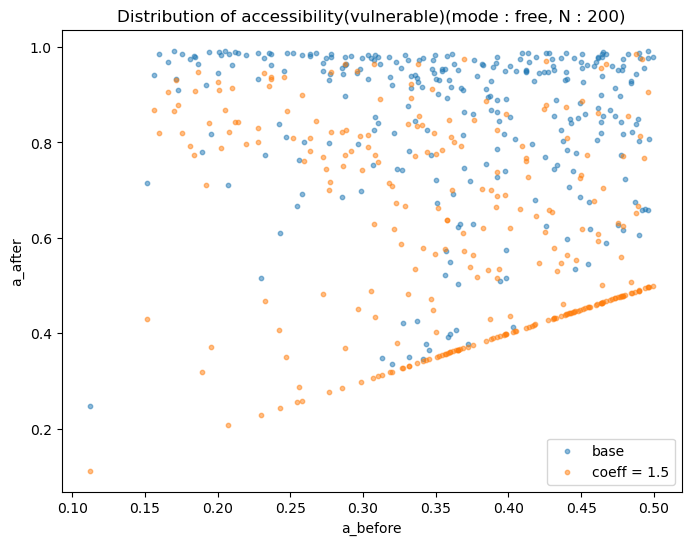

In [253]:
temp = df_grid_2[df_grid_2['grid_id'].isin(df_grid_only_base_2[df_grid_only_base_2['vulnerable'] == True]['grid_id'])]

# coeff = 1.5, accessibility scatter

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    df_grid_only_base_2[df_grid_only_base_2['vulnerable'] == True]['a_before'],
    df_grid_only_base_2[df_grid_only_base_2['vulnerable'] == True]['a_after'],
    s=10,
    alpha=0.5,
    label='base'
)

ax.scatter(
    temp['a_before'],
    temp['a_after'],
    s=10,
    alpha=0.5,
    label='coeff = 1.5'
)

ax.set_title(f'Distribution of accessibility(vulnerable)(mode : {mode}, N : {n})')
ax.set_xlabel('a_before')
ax.set_ylabel('a_after')
ax.legend()

plt.show()

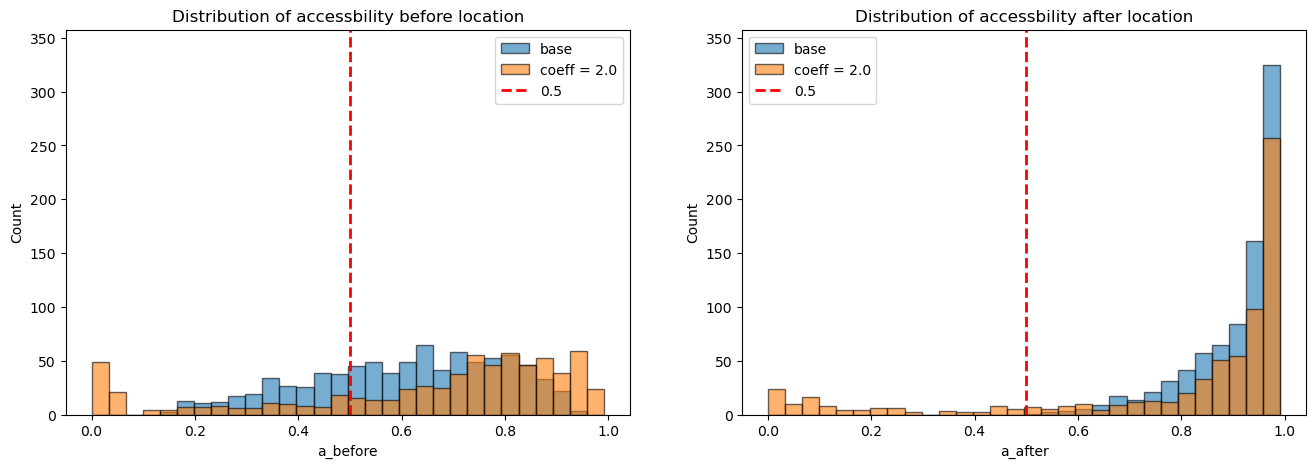

In [226]:
fig, axes = plt.subplots(1,2,figsize=(16, 5))

ax1, ax2 = axes

data_all = np.concatenate([
    df_grid_only_base_3['a_before'],
    df_grid_only_3['a_before']
])

bins = np.histogram_bin_edges(data_all, bins=30)

ax1.hist(
    df_grid_only_base_3['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax1.hist(
    df_grid_only_3['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 2.0',
    edgecolor='black'
)

ax1.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax1.set_title('Distribution of accessbility before location')
ax1.set_xlabel('a_before')
ax1.set_ylabel('Count')
ax1.legend()

ax2.hist(
    df_grid_only_base_3['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax2.hist(
    df_grid_only_3['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 2.0',
    edgecolor='black'
)

ax2.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax2.set_title('Distribution of accessbility after location')
ax2.set_xlabel('a_after')
ax2.set_ylabel('Count')
ax2.legend()

# 히스토그램 count 계산 (그리지는 않음)
c1, _ = np.histogram(df_grid_only_base_3['a_before'].dropna(), bins=bins)
c2, _ = np.histogram(df_grid_only_3['a_before'].dropna(), bins=bins)
c3, _ = np.histogram(df_grid_only_base_3['a_after'].dropna(), bins=bins)
c4, _ = np.histogram(df_grid_only_3['a_after'].dropna(), bins=bins)

ymax = max(c1.max(), c2.max(), c3.max(), c4.max())

ax1.set_ylim(0, ymax * 1.1)
ax2.set_ylim(0, ymax * 1.1)

plt.show()

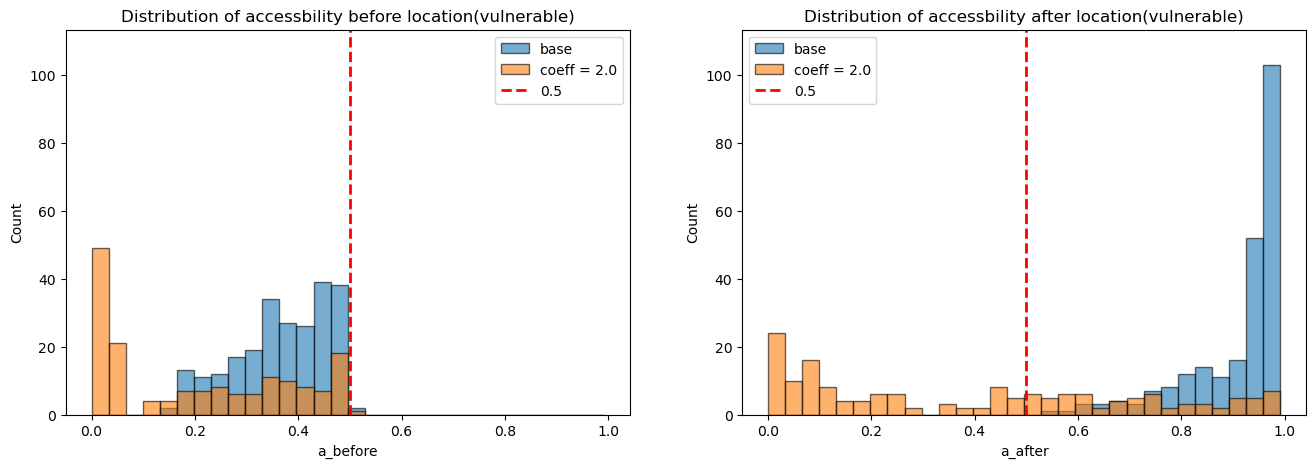

In [227]:
fig, axes = plt.subplots(1,2,figsize=(16, 5))

ax1, ax2 = axes

data_all = np.concatenate([
    df_grid_only_base_3['a_before'],
    df_grid_only_3['a_before']
])

bins = np.histogram_bin_edges(data_all, bins=30)

ax1.hist(
    df_grid_only_base_3[df_grid_only_base_3['vulnerable'] == True]['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax1.hist(
    df_grid_only_3[df_grid_only_3['vulnerable'] == True]['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 2.0',
    edgecolor='black'
)

ax1.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax1.set_title('Distribution of accessbility before location(vulnerable)')
ax1.set_xlabel('a_before')
ax1.set_ylabel('Count')
ax1.legend()

ax2.hist(
    df_grid_only_base_3[df_grid_only_base_3['vulnerable'] == True]['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax2.hist(
    df_grid_only_3[df_grid_only_3['vulnerable'] == True]['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 2.0',
    edgecolor='black'
)

ax2.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax2.set_title('Distribution of accessbility after location(vulnerable)')
ax2.set_xlabel('a_after')
ax2.set_ylabel('Count')
ax2.legend()

# 히스토그램 count 계산 (그리지는 않음)
c1, _ = np.histogram(df_grid_only_base_3[df_grid_only_base_3['vulnerable'] == True]['a_before'].dropna(), bins=bins)
c2, _ = np.histogram(df_grid_only_3[df_grid_only_3['vulnerable'] == True]['a_before'].dropna(), bins=bins)
c3, _ = np.histogram(df_grid_only_base_3[df_grid_only_base_3['vulnerable'] == True]['a_after'].dropna(), bins=bins)
c4, _ = np.histogram(df_grid_only_3[df_grid_only_3['vulnerable'] == True]['a_after'].dropna(), bins=bins)

ymax = max(c1.max(), c2.max(), c3.max(), c4.max())

ax1.set_ylim(0, ymax * 1.1)
ax2.set_ylim(0, ymax * 1.1)

plt.show()

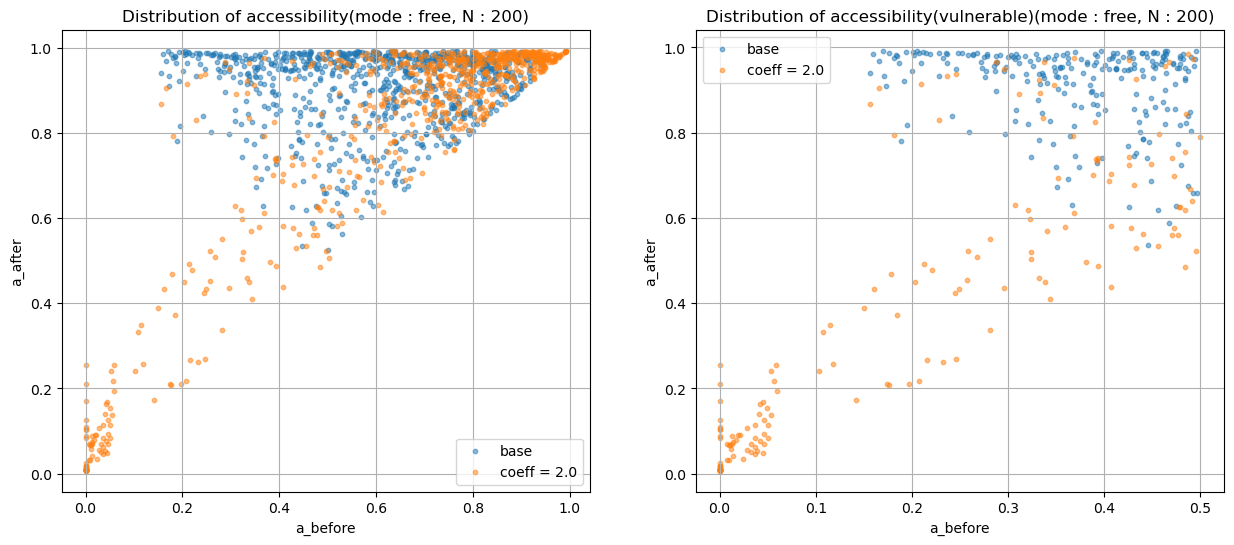

In [228]:
# coeff = 2.0, accessibility scatter

fig, axes = plt.subplots(1,2,figsize=(15, 6))

ax1, ax2 = axes

ax1.scatter(
    df_grid_only_base_3['a_before'],
    df_grid_only_base_3['a_after'],
    s=10,
    alpha=0.5,
    label='base'
)

ax1.scatter(
    df_grid_only_3['a_before'],
    df_grid_only_3['a_after'],
    s=10,
    alpha=0.5,
    label='coeff = 2.0'
)

ax1.set_title(f'Distribution of accessibility(mode : {mode}, N : {n})')
ax1.set_xlabel('a_before')
ax1.set_ylabel('a_after')
ax1.legend()
ax1.grid(True)

ax2.scatter(
    df_grid_only_base_3[df_grid_only_base_3['vulnerable'] == True]['a_before'],
    df_grid_only_base_3[df_grid_only_base_3['vulnerable'] == True]['a_after'],
    s=10,
    alpha=0.5,
    label='base'
)

ax2.scatter(
    df_grid_only_3[df_grid_only_3['vulnerable'] == True]['a_before'],
    df_grid_only_3[df_grid_only_3['vulnerable'] == True]['a_after'],
    s=10,
    alpha=0.5,
    label='coeff = 2.0'
)
ax2.set_title(f'Distribution of accessibility(vulnerable)(mode : {mode}, N : {n})')
ax2.set_xlabel('a_before')
ax2.set_ylabel('a_after')
ax2.legend()
ax2.grid(True)

plt.show()

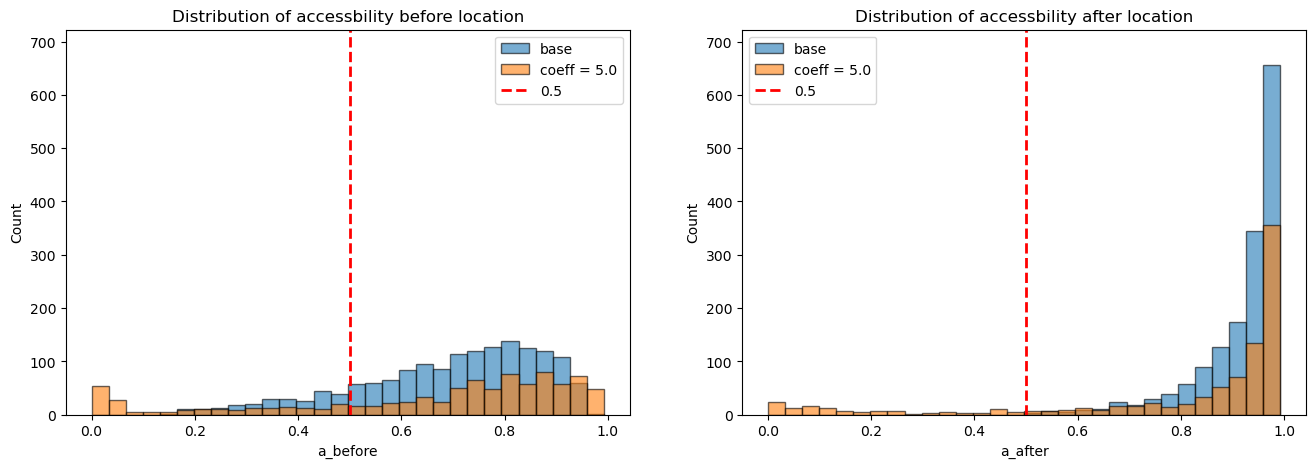

In [229]:
fig, axes = plt.subplots(1,2,figsize=(16, 5))

ax1, ax2 = axes

data_all = np.concatenate([
    df_grid_only_base_4['a_before'],
    df_grid_only_4['a_before']
])

bins = np.histogram_bin_edges(data_all, bins=30)

ax1.hist(
    df_grid_only_base_4['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax1.hist(
    df_grid_only_4['a_before'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 5.0',
    edgecolor='black'
)

ax1.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax1.set_title('Distribution of accessbility before location')
ax1.set_xlabel('a_before')
ax1.set_ylabel('Count')
ax1.legend()

ax2.hist(
    df_grid_only_base_4['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='base',
    edgecolor='black'
)

ax2.hist(
    df_grid_only_4['a_after'].dropna(),
    bins=bins,
    alpha=0.6,
    label='coeff = 5.0',
    edgecolor='black'
)

ax2.axvline(
    0.5,
    color='red',
    linestyle='--',
    linewidth=2,
    label='0.5'
)

ax2.set_title('Distribution of accessbility after location')
ax2.set_xlabel('a_after')
ax2.set_ylabel('Count')
ax2.legend()

# 히스토그램 count 계산 (그리지는 않음)
c1, _ = np.histogram(df_grid_only_base_4['a_before'].dropna(), bins=bins)
c2, _ = np.histogram(df_grid_only_4['a_before'].dropna(), bins=bins)
c3, _ = np.histogram(df_grid_only_base_4['a_after'].dropna(), bins=bins)
c4, _ = np.histogram(df_grid_only_4['a_after'].dropna(), bins=bins)

ymax = max(c1.max(), c2.max(), c3.max(), c4.max())

ax1.set_ylim(0, ymax * 1.1)
ax2.set_ylim(0, ymax * 1.1)

plt.show()

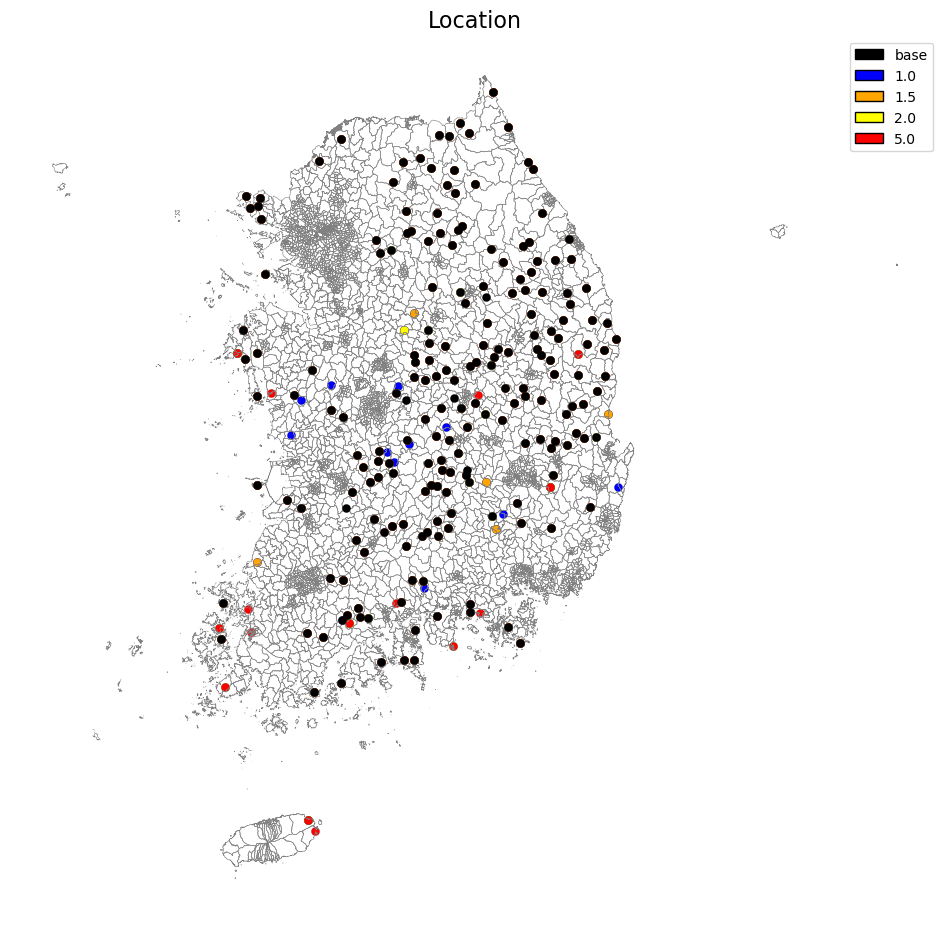

In [230]:
fig, ax = plt.subplots(figsize=(12, 14))

# 보건소

gdf_bogun_0.plot(
    ax=ax,
    facecolor='black',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 10
)

gdf_bogun_1.plot(
    ax=ax,
    facecolor='blue',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_2.plot(
    ax=ax,
    facecolor='orange',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_3.plot(
    ax=ax,
    facecolor='yellow',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

gdf_bogun_4.plot(
    ax=ax,
    facecolor='red',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

legend_elements = [
    Patch(facecolor='black',  edgecolor='black', label='base'),
    Patch(facecolor='blue',   edgecolor='black', label='1.0'),
    Patch(facecolor='orange', edgecolor='black', label='1.5'),
    Patch(facecolor='yellow', edgecolor='black', label='2.0'),
    Patch(facecolor='red',    edgecolor='black', label='5.0'),
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    fontsize=10,
    title_fontsize=11
)

ax.set_title("Location", fontsize=16)
ax.axis('off')

plt.show()

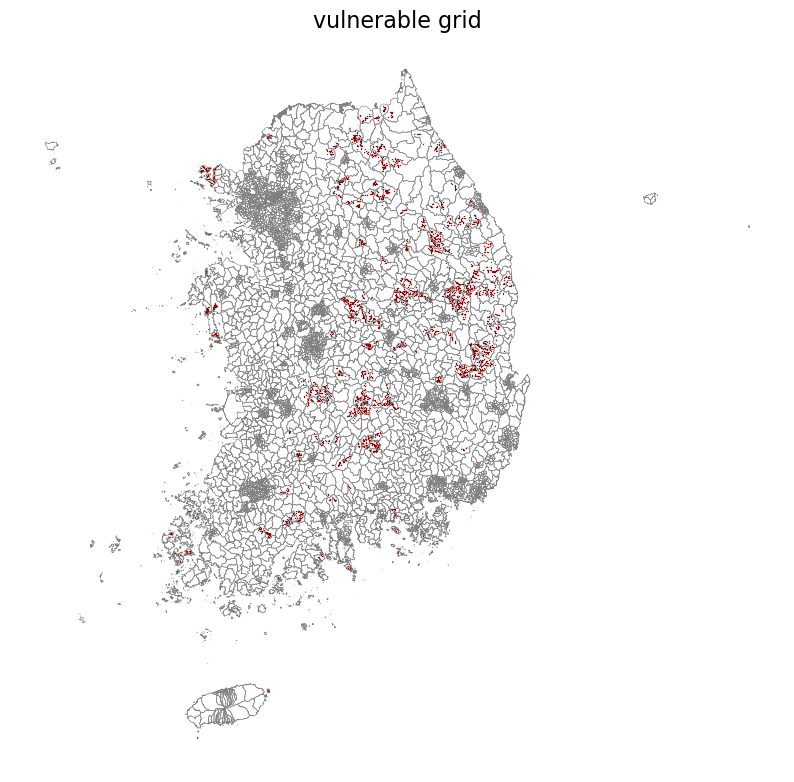

In [231]:
fig, ax = plt.subplots(figsize=(10, 10))

# 취약격자자
df_grid_vulnerable.plot(
    ax=ax,
    facecolor='red',
    edgecolor='black',
    linewidth=0.1,
    alpha=1.0,
    zorder = 2
)

# 읍면동 경계
gdf_emd.boundary.plot(
    ax=ax,
    linewidth=0.4,
    edgecolor='gray'
)

ax.set_title("vulnerable grid", fontsize=16)
ax.axis('off')

plt.show()

In [232]:
df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_1))][df_grid['vulnerable'] == True][df_grid['resolved'] == True]
grid_id = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_1))][df_grid['vulnerable'] == True]['grid_id']
len(df_grid_1[df_grid_1['grid_id'].isin(grid_id)][df_grid_1['resolved'] == True])

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)


290

In [233]:
df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_2))][df_grid['vulnerable'] == True]
grid_id = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_2))][df_grid['vulnerable'] == True]['grid_id']
len(df_grid_2[df_grid_2['grid_id'].isin(grid_id)][df_grid_2['resolved'] == True])

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)


156

In [234]:
df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_3))][df_grid['vulnerable'] == True][df_grid['resolved'] == True]
grid_id = df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_3))][df_grid['vulnerable'] == True]['grid_id']
len(df_grid_3[df_grid_3['grid_id'].isin(grid_id)][df_grid_3['resolved'] == True])

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)


170

In [235]:
print(f"location 이전 취약 격자 접근성 평균(기존 / 1.0) : {df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_1))][df_grid['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약 격자 접근성 평균(기존 / 1.0) : {df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_1))][df_grid['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이전 취약 격자 접근성 평균(기존 / 1.5) : {df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_2))][df_grid['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약 격자 접근성 평균(기존 / 1.5) : {df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_2))][df_grid['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이전 취약 격자 접근성 평균(기존 / 2.0) : {df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_3))][df_grid['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약 격자 접근성 평균(기존 / 2.0) : {df_grid[df_grid['chosen_facility'].isin(set(selected) - set(selected_3))][df_grid['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이전 취약격자 접근성 평균 : {df_grid[df_grid['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약격자 접근성 평균 : {df_grid[df_grid['vulnerable'] == True]['a_after'].mean()}")
print(f"분산 : {np.var(df_grid[df_grid['vulnerable'] == True]['a_after'])}")

location 이전 취약 격자 접근성 평균(기존 / 1.0) : 0.374175760529039
location 이후 취약 격자 접근성 평균(기존 / 1.0) : 0.8311995728914616
location 이전 취약 격자 접근성 평균(기존 / 1.5) : 0.3625084784432611
location 이후 취약 격자 접근성 평균(기존 / 1.5) : 0.8496813540028194
location 이전 취약 격자 접근성 평균(기존 / 2.0) : 0.3668965153656869
location 이후 취약 격자 접근성 평균(기존 / 2.0) : 0.9115964597694983
location 이전 취약격자 접근성 평균 : 0.2526205815183378
location 이후 취약격자 접근성 평균 : 0.7420204269237056
분산 : 0.07496269497657262


c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaco

In [236]:
df_grid_1[df_grid_1['chosen_facility'].isin(set(selected_1) - set(selected))][df_grid_1['vulnerable'] == True]
# grid_id_1 = df_grid_1[df_grid_1['chosen_facility'].isin(set(selected_1) - set(selected))][df_grid_1['vulnerable'] == True]['grid_id']
# df_grid[df_grid['grid_id'].isin(grid_id_1)][df_grid['resolved'] == True]

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)


,grid_id,a_before,z,a_after,delta,chosen_facility,geometry,grid_centroid,population,EMD_CD,coefficient,adjusted_population,vulnerable,resolved,improved accessibility
993,14525,0.014318,0.025901,0.040219,0.080889,196,"POLYGON ((872500 1854000, 872500 1854500, 8730...",POINT (872749.9999999995 1854250.0000000005),8,44825330,1.290220,10.321762,True,False,0.834917
994,14534,0.007790,0.023410,0.031200,0.088375,196,"POLYGON ((872000 1853500, 872000 1854000, 8725...",POINT (872249.9999999993 1853750.0000000002),23,44825330,1.290220,29.675067,True,False,2.622532
995,14535,0.009227,0.022377,0.031604,0.081719,196,"POLYGON ((872000 1854000, 872000 1854500, 8725...",POINT (872250.0000000008 1854249.9999999981),48,44825330,1.290220,61.930574,True,False,5.060925
996,14536,0.000000,0.024496,0.024496,0.156512,196,"POLYGON ((871500 1853500, 871500 1854000, 8720...",POINT (871750.0000000007 1853750.000000001),5,44825330,1.290220,6.451101,True,False,1.009672
997,14566,0.343877,0.066291,0.410168,0.054033,196,"POLYGON ((878000 1853000, 878000 1853500, 8785...",POINT (878249.9999999998 1853250.0000000002),13,44825330,1.290220,16.772864,True,False,0.906288
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49237,338218,0.323804,0.180421,0.504225,0.141050,868,"POLYGON ((1130500 1759500, 1130500 1760000, 11...",POINT (1130750.000000001 1759750.000000001),5,47290340,1.314381,6.571904,True,True,0.926969
49253,338282,0.457052,0.338716,0.795768,0.216002,868,"POLYGON ((1129500 1758000, 1129500 1758500, 11...",POINT (1129749.9999999995 1758250),23,47290340,1.314381,30.230758,True,True,6.529896
51979,365829,0.390996,0.472836,0.863833,0.304129,71,"POLYGON ((1171000 1759500, 1171000 1760000, 11...",POINT (1171250.000000001 1759749.9999999995),13,47130315,1.146423,14.903498,True,True,4.532585
52002,365904,0.459064,0.325041,0.784105,0.207954,71,"POLYGON ((1171500 1761500, 1171500 1762000, 11...",POINT (1171749.9999999993 1761750.000000001),13,47130315,1.146423,14.903498,True,True,3.099246


In [237]:
df_grid_2[df_grid_2['chosen_facility'].isin(set(selected_2) - set(selected))][df_grid_2['vulnerable'] == True]
# grid_id_2 = df_grid_2[df_grid_2['chosen_facility'].isin(set(selected_2) - set(selected))][df_grid_2['vulnerable'] == True]['grid_id']
# df_grid[df_grid['grid_id'].isin(grid_id_2)][df_grid['resolved'] == True]

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)


,grid_id,a_before,z,a_after,delta,chosen_facility,geometry,grid_centroid,population,EMD_CD,coefficient,adjusted_population,vulnerable,resolved,improved accessibility
993,14525,0.014318,0.025901,0.040219,0.080889,196,"POLYGON ((872500 1854000, 872500 1854500, 8730...",POINT (872749.9999999995 1854250.0000000005),8,44825330,1.290220,10.321762,True,False,0.834917
994,14534,0.007790,0.023410,0.031200,0.088375,196,"POLYGON ((872000 1853500, 872000 1854000, 8725...",POINT (872249.9999999993 1853750.0000000002),23,44825330,1.290220,29.675067,True,False,2.622532
995,14535,0.009227,0.022377,0.031604,0.081719,196,"POLYGON ((872000 1854000, 872000 1854500, 8725...",POINT (872250.0000000008 1854249.9999999981),48,44825330,1.290220,61.930574,True,False,5.060925
996,14536,0.000000,0.024496,0.024496,0.156512,196,"POLYGON ((871500 1853500, 871500 1854000, 8720...",POINT (871750.0000000007 1853750.000000001),5,44825330,1.290220,6.451101,True,False,1.009672
997,14566,0.343877,0.066291,0.410168,0.054033,196,"POLYGON ((878000 1853000, 878000 1853500, 8785...",POINT (878249.9999999998 1853250.0000000002),13,44825330,1.290220,16.772864,True,False,0.906288
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54592,382018,0.338239,0.110479,0.448718,0.088281,964,"POLYGON ((1143000 1863500, 1143000 1864000, 11...",POINT (1143250.000000001 1863749.999999999),5,47760330,1.314898,6.574488,True,False,0.580402
54599,382064,0.483701,0.134535,0.618236,0.090794,964,"POLYGON ((1144000 1862500, 1144000 1863000, 11...",POINT (1144250.0000000005 1862750.0000000002),5,47760330,1.314898,6.574488,True,True,0.596921
54600,382065,0.428164,0.147967,0.576131,0.104690,964,"POLYGON ((1144000 1863000, 1144000 1863500, 11...",POINT (1144250.0000000014 1863249.9999999998),5,47760330,1.314898,6.574488,True,True,0.688286
54601,382069,0.114871,0.233591,0.348462,0.251380,964,"POLYGON ((1144000 1865000, 1144000 1865500, 11...",POINT (1144249.9999999998 1865249.9999999995),5,47760330,1.314898,6.574488,True,False,1.652696


In [238]:
df_grid_3[df_grid_3['chosen_facility'].isin(set(selected_3) - set(selected))][df_grid_3['vulnerable'] == True][df_grid_3['resolved'] == True]
# grid_id_3 = df_grid_3[df_grid_3['chosen_facility'].isin(set(selected_3) - set(selected))][df_grid_3['vulnerable'] == True]['grid_id']
# df_grid[df_grid['grid_id'].isin(grid_id_3)][df_grid['resolved'] == True]

c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)


,grid_id,a_before,z,a_after,delta,chosen_facility,geometry,grid_centroid,population,EMD_CD,coefficient,adjusted_population,vulnerable,resolved,improved accessibility
999,14568,0.455938,0.077554,0.533493,0.055174,196,"POLYGON ((878000 1854000, 878000 1854500, 8785...",POINT (878250.0000000007 1854249.9999999998),372,44825330,1.290220,479.961947,True,True,26.481321
1045,14731,0.472470,0.104701,0.577170,0.072353,196,"POLYGON ((878500 1854000, 878500 1854500, 8790...",POINT (878750.0000000008 1854249.999999999),43,44825330,1.290220,55.479472,True,True,4.014111
1780,24960,0.491414,0.148507,0.639921,0.098941,159,"POLYGON ((948000 1502000, 948000 1502500, 9485...",POINT (948250.0000000012 1502250),43,50110330,1.097467,47.191091,True,True,4.669144
1785,24965,0.324215,0.194970,0.519185,0.151146,159,"POLYGON ((949000 1502000, 949000 1502500, 9495...",POINT (949249.9999999992 1502250),53,50110330,1.097467,58.165763,True,True,8.791535
1786,24966,0.268062,0.241228,0.509290,0.195898,159,"POLYGON ((949000 1502500, 949000 1503000, 9495...",POINT (949250.0000000007 1502749.9999999995),68,50110330,1.097467,74.627771,True,True,14.619444
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54570,381954,0.431291,0.245401,0.676692,0.165886,964,"POLYGON ((1145500 1863000, 1145500 1863500, 11...",POINT (1145749.999999999 1863250.0000000005),8,47760330,1.314898,10.519180,True,True,1.744982
54571,381955,0.358930,0.219115,0.578045,0.161185,964,"POLYGON ((1145500 1863500, 1145500 1864000, 11...",POINT (1145750 1863749.9999999998),8,47760330,1.314898,10.519180,True,True,1.695535
54583,381987,0.472263,0.226722,0.698985,0.148839,964,"POLYGON ((1145000 1862500, 1145000 1863000, 11...",POINT (1145250.0000000007 1862750.0000000002),5,47760330,1.314898,6.574488,True,True,0.978541
54599,382064,0.483701,0.134535,0.618236,0.090794,964,"POLYGON ((1144000 1862500, 1144000 1863000, 11...",POINT (1144250.0000000005 1862750.0000000002),5,47760330,1.314898,6.574488,True,True,0.596921


In [239]:
print(f"location 이전 취약격자 접근성 평균(coeff : 1.0 / 기존) : {df_grid_1[df_grid_1['chosen_facility'].isin(set(selected_1) - set(selected))][df_grid_1['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 1.0 / 기존) : {df_grid_1[df_grid_1['chosen_facility'].isin(set(selected_1) - set(selected))][df_grid_1['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 1.0) : {df_grid_1[df_grid_1['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이전 취약격자 접근성 평균(coeff : 1.5 / 기존) : {df_grid_2[df_grid_2['chosen_facility'].isin(set(selected_2) - set(selected))][df_grid_2['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 1.5 / 기존) : {df_grid_2[df_grid_2['chosen_facility'].isin(set(selected_2) - set(selected))][df_grid_2['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 1.5) : {df_grid_2[df_grid_2['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이전 취약격자 접근성 평균(coeff : 2.0 / 기존) : {df_grid_3[df_grid_3['chosen_facility'].isin(set(selected_3) - set(selected))][df_grid_3['vulnerable'] == True]['a_before'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 2.0 / 기존) : {df_grid_3[df_grid_3['chosen_facility'].isin(set(selected_3) - set(selected))][df_grid_3['vulnerable'] == True]['a_after'].mean()}")
print(f"location 이후 취약격자 접근성 평균(coeff : 2.0) : {df_grid_3[df_grid_3['vulnerable'] == True]['a_after'].mean()}")

location 이전 취약격자 접근성 평균(coeff : 1.0 / 기존) : 0.38471394624655453
location 이후 취약격자 접근성 평균(coeff : 1.0 / 기존) : 0.7951042006765744
location 이후 취약격자 접근성 평균(coeff : 1.0) : 0.7288058913310309
location 이전 취약격자 접근성 평균(coeff : 1.5 / 기존) : 0.3307233892451917
location 이후 취약격자 접근성 평균(coeff : 1.5 / 기존) : 0.6063796150886834
location 이후 취약격자 접근성 평균(coeff : 1.5) : 0.7362996671480346
location 이전 취약격자 접근성 평균(coeff : 2.0 / 기존) : 0.20267692927950703


c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaconda3\envs\geo\lib\site-packages\geopandas\geodataframe.py:1891: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)
c:\Users\hshoo\anaco

location 이후 취약격자 접근성 평균(coeff : 2.0 / 기존) : 0.3918548711753291
location 이후 취약격자 접근성 평균(coeff : 2.0) : 0.7377285893464833


In [240]:
print(f"해소 취약격자 갯수 : {len(df_grid_vulnerable[df_grid_vulnerable['a_after'] > 0.5])}")
print(f"접근성 상승 취약격자 갯수 : {len(df_grid_vulnerable[df_grid_vulnerable['z'] > 0])}")
print(f"취약격자 접근성 향상 평균 : {df_grid_vulnerable['z'].sum()/len(df_grid_vulnerable)}")
print(f"취약격자 접근성 분산 : {np.var(df_grid_vulnerable['a_after'])}")

해소 취약격자 갯수 : 8009
접근성 상승 취약격자 갯수 : 9571
취약격자 접근성 향상 평균 : 0.48939984540536774
취약격자 접근성 분산 : 0.07496269497657262


In [241]:
print(f"해소 취약격자 갯수 : {len(df_grid_vulnerable_1[df_grid_vulnerable_1['a_after'] > 0.5])}")
print(f"접근성 상승 취약격자 갯수 : {len(df_grid_vulnerable_1[df_grid_vulnerable_1['z'] > 0])}")
print(f"취약격자 접근성 향상 평균 : {df_grid_vulnerable_1['z'].sum()/len(df_grid_vulnerable_1)}")
print(f"취약격자 접근성 분산 : {np.var(df_grid_vulnerable_1['a_after'])}")

해소 취약격자 갯수 : 7779
접근성 상승 취약격자 갯수 : 9371
취약격자 접근성 향상 평균 : 0.4761853098126932
취약격자 접근성 분산 : 0.07673463596804886


In [242]:
print(f"해소 취약격자 갯수 : {len(df_grid_vulnerable_2[df_grid_vulnerable_2['a_after'] > 0.5])}")
print(f"접근성 상승 취약격자 갯수 : {len(df_grid_vulnerable_2[df_grid_vulnerable_2['z'] > 0])}")
print(f"취약격자 접근성 향상 평균 : {df_grid_vulnerable_2['z'].sum()/len(df_grid_vulnerable_2)}")
print(f"취약격자 접근성 분산 : {np.var(df_grid_vulnerable_2['a_after'])}")

해소 취약격자 갯수 : 7931
접근성 상승 취약격자 갯수 : 9533
취약격자 접근성 향상 평균 : 0.4836790856296969
취약격자 접근성 분산 : 0.07495488198927365


In [243]:
print(f"해소 취약격자 갯수 : {len(df_grid_vulnerable_3[df_grid_vulnerable_3['a_after'] > 0.5])}")
print(f"접근성 상승 취약격자 갯수 : {len(df_grid_vulnerable_3[df_grid_vulnerable_3['z'] > 0])}")
print(f"취약격자 접근성 향상 평균 : {df_grid_vulnerable_3['z'].sum()/len(df_grid_vulnerable_3)}")
print(f"취약격자 접근성 분산 : {np.var(df_grid_vulnerable_3['a_after'])}")

해소 취약격자 갯수 : 7972
접근성 상승 취약격자 갯수 : 9655
취약격자 접근성 향상 평균 : 0.48510800782814545
취약격자 접근성 분산 : 0.07382862239307547


In [ ]:
# 수정사항